# Random subset sums and lottery tickets

The computations behind the README. Every number and figure there comes from a cell here, the explanations are in the README.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.stats import spearmanr
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from utils import plots, theory
from utils.coverage_runs import CoverageRuns
from utils.pruning import TicketLinear
plots.use_style()

Covering radius $\rho_n$ and $N(\varepsilon)$ as in the README. Data from `main.py`: 20000 draws of 40 weights on a $2^{-20}$ grid, exact down to about $2^{-16}$.

In [2]:
data = np.load("data/coverage.npz")
runs = CoverageRuns(data["weights"], data["radii"])
runs.radii.shape

(20000, 40)

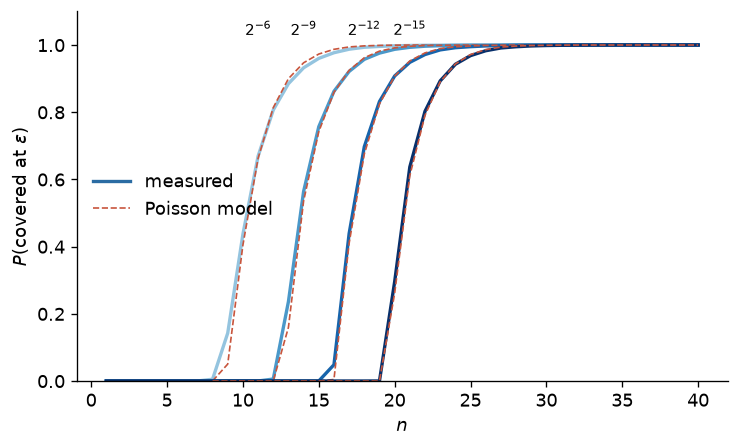

In [3]:
plots.plot_transition(runs, exponents=[6, 9, 12, 15])
plt.savefig("figures/transition.png", dpi=150, bbox_inches="tight")

Solid: measured. Dashed: Poisson model, nothing fitted. Then the largest gap between the two.

In [4]:
eps = 2.0**-12
print(" n  measured  model")
for n in (17, 18, 19, 20, 22):
    print(f"{n:2d}  {(runs.radii <= eps).mean(axis=0)[n - 1]:8.3f}  {theory.coverage_given_weights(n, eps, runs.weights).mean():5.3f}")
gaps = [
    abs((runs.radii <= 2.0**-k).mean(axis=0)[n - 1] - theory.coverage_given_weights(n, 2.0**-k, runs.weights).mean())
    for k in range(6, 16)
    for n in range(8, runs.n_max + 1)
]
print(f"largest gap for k = 6..15, n >= 8: {max(gaps):.3f}")

 n  measured  model
17     0.439  0.410


18     0.697  0.675
19     0.832  0.825


20     0.908  0.907
22     0.972  0.976


largest gap for k = 6..15, n >= 8: 0.092


Slow draws against the imbalance $t = |\sum_i x_i| / \sqrt{\sum_i x_i^2}$.

spearman: 0.84, unfinished draws: 0
t in [0, 1): mean N = 17.3  (13458 draws)
t in [1, 2): mean N = 19.6  (5681 draws)
t in [2, 3): mean N = 22.5  (829 draws)


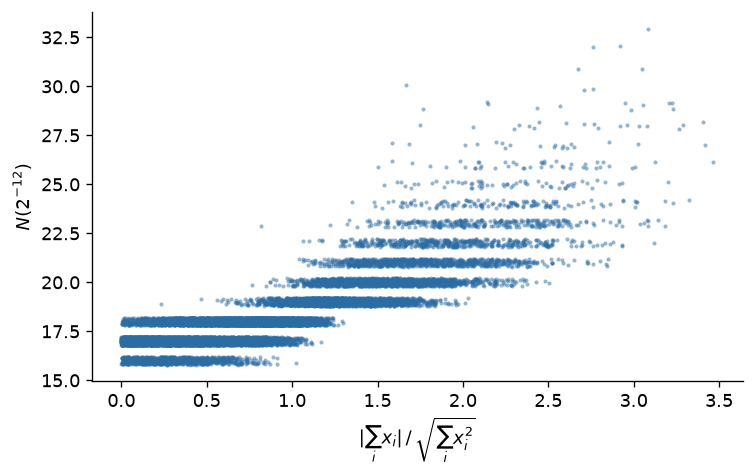

In [5]:
plots.plot_offset(runs, k=12)
hits = runs.first_hit(eps)
offset = runs.standardised_offset(18)
done = np.isfinite(hits)
# rank correlation, so the draws that never finished can stay in
capped = np.where(done, hits, runs.n_max + 1)
print(f"spearman: {spearmanr(offset, capped).statistic:.2f}, unfinished draws: {(~done).sum()}")
for low, high in [(0, 1), (1, 2), (2, 3)]:
    picked = done & (offset >= low) & (offset < high)
    print(f"t in [{low}, {high}): mean N = {hits[picked].mean():.1f}  ({picked.sum()} draws)")

Median and tail of $N(\varepsilon)$, against the first order $\log_2(1/\varepsilon) + \log_2 \ln(1/\varepsilon)$.

median slope over k = 6..16: 1.14
median - first order: [2.9 2.7 2.5 2.4 2.2 3.1 2.9 2.8 2.7 2.6 2.5]


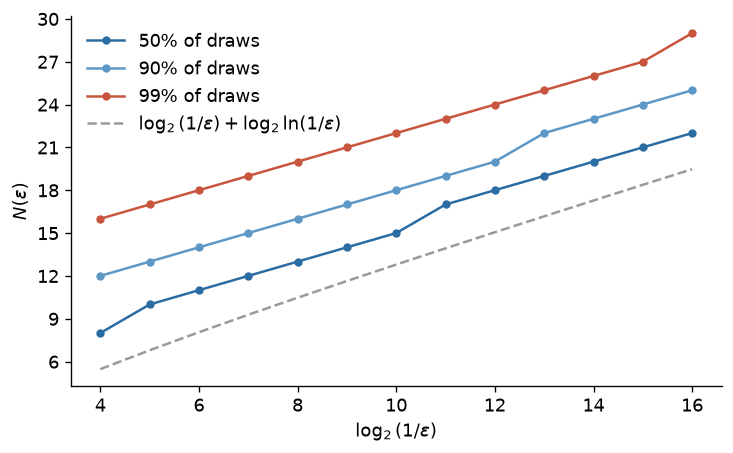

In [6]:
plots.plot_thresholds(runs, exponents=np.arange(4, 17))
ks = np.arange(6, 17)
medians = np.array([runs.threshold(2.0**-k) for k in ks])
print(f"median slope over k = 6..16: {np.polyfit(ks, medians, 1)[0]:.2f}")
print("median - first order:", np.round(medians - (ks + np.log2(np.log(2.0**ks))), 1))

$C = N / \ln(1/\varepsilon)$ for the $1 - \varepsilon$ guarantee. These are extreme quantiles, so bootstrap intervals.

In [7]:
# the 1 - eps quantile needs a few failing draws, 20000 draws is enough up to 2^-11
exponents = np.arange(3, 12)
all_hits = {k: runs.first_hit(2.0**-k) for k in exponents}
worst = np.array([runs.threshold(2.0**-k, 1 - 2.0**-k) for k in exponents])
median = np.array([runs.threshold(2.0**-k) for k in exponents])
rng = np.random.default_rng(0)
boots = np.array(
    [
        [np.quantile(all_hits[k][idx], 1 - 2.0**-k, method="higher") for k in exponents]
        for idx in (rng.integers(0, runs.trials, runs.trials) for _ in range(2000))
    ]
)
low, high = np.sort(boots, axis=0)[[50, 1949]]
print(" eps  median     N    95% interval     C  from guarantee")
for i, k in enumerate(exponents):
    share = 1 - median[i] / worst[i]
    print(f"2^-{k}  {median[i]:6.0f}  {worst[i]:4.0f}  [{low[i]:3.0f}, {high[i]:3.0f}]  {worst[i] / (k * np.log(2)):12.2f}  {share:14.0%}")

 eps  median     N    95% interval     C  from guarantee
2^-3       7    10  [ 10,  10]          4.81             30%
2^-4       8    13  [ 12,  13]          4.69             38%
2^-5      10    15  [ 15,  15]          4.33             33%
2^-6      11    17  [ 17,  17]          4.09             35%
2^-7      12    19  [ 19,  20]          3.92             37%
2^-8      13    22  [ 21,  22]          3.97             41%
2^-9      14    24  [ 23,  24]          3.85             42%
2^-10      15    26  [ 25,  27]          3.75             42%
2^-11      17    28  [ 28,  30]          3.67             39%


slope, 1 - eps: 2.23  [2.15, 2.42]
slope, median:  1.18


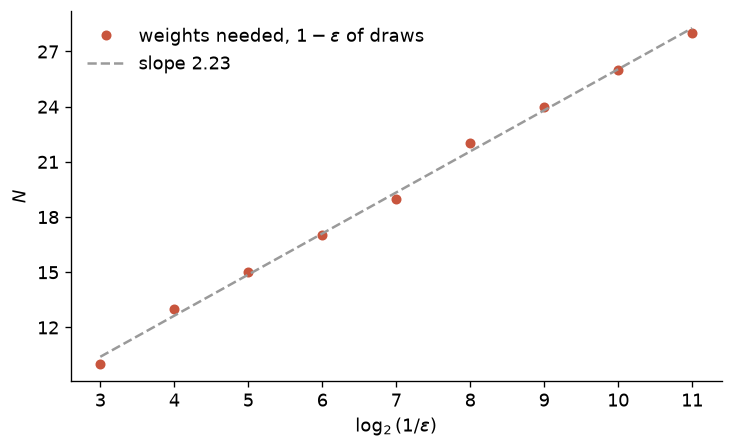

In [8]:
fit = exponents >= 3
slopes = np.array([np.polyfit(exponents[fit], b[fit], 1)[0] for b in boots])
slope_low, slope_high = np.sort(slopes)[[50, 1949]]
print(f"slope, 1 - eps: {np.polyfit(exponents[fit], worst[fit], 1)[0]:.2f}  [{slope_low:.2f}, {slope_high:.2f}]")
print(f"slope, median:  {np.polyfit(exponents[fit], median[fit], 1)[0]:.2f}")
plots.plot_worst_case(exponents[fit], worst[fit])
plt.savefig("figures/guarantee.png", dpi=150, bbox_inches="tight")

The slope roughly doubles compared to the median. The prediction $C \to 2 / \ln 2$ is explained in the README. Its key step is the rate at which $f(x) = \min_\theta \frac{1}{n} \sum_i \log_2(1 + e^{\theta x_i})$ falls below $a$, checked here against $\ln 2 \, (1 - a)$.

In [9]:
# rate of P(f(x) < a) for x uniform: Cramer for each theta, then the best theta
x = np.linspace(-1, 1, 20001)

def rate(a):
    def given_theta(theta):
        g = np.log2(1 + np.exp(theta * x))
        def dual(lam):
            v = -lam * g
            return lam * a + v.max() + np.log(np.trapezoid(np.exp(v - v.max()), x) / 2)
        return -minimize_scalar(dual, bounds=(0, 400), method="bounded").fun
    return minimize_scalar(given_theta, bounds=(0, 60), method="bounded").fun

for a in (0.1, 0.25, 0.5, 0.75, 0.9):
    print(f"a = {a:.2f}  rate {rate(a):.4f}  ln2 (1 - a) {np.log(2) * (1 - a):.4f}")

a = 0.10  rate 0.6238  ln2 (1 - a) 0.6238
a = 0.25  rate 0.5199  ln2 (1 - a) 0.5199
a = 0.50  rate 0.3466  ln2 (1 - a) 0.3466
a = 0.75  rate 0.1733  ln2 (1 - a) 0.1733


a = 0.90  rate 0.0693  ln2 (1 - a) 0.0693


Ticket demo: a logistic regression on digits, rebuilt from pools of random weights by pruning only.

In [10]:
X, y = load_digits(return_X_y=True)
def split(seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=seed, stratify=y)
    scaler = StandardScaler().fit(X_train)
    return scaler.transform(X_train), scaler.transform(X_test), y_train, y_test
splits = [split(seed) for seed in range(5)]
models = [LogisticRegression(max_iter=2000).fit(s[0], s[2]) for s in splits]
target_accuracy = np.mean([m.score(s[1], s[3]) for m, s in zip(models, splits)])
print(f"target, mean of 5 splits: {target_accuracy:.4f}")

target, mean of 5 splits: 0.9681


pool  accuracy  worst ticket  sparsity  max error
   2    0.7710        0.6796      0.80     0.8059
   4    0.9195        0.9019      0.71     0.9172
   6    0.9585        0.9389      0.65     0.4939
   8    0.9643        0.9537      0.61     0.3420
  10    0.9644        0.9481      0.59     0.2897
  12    0.9681        0.9537      0.57     0.0957
  14    0.9683        0.9556      0.56     0.0145
  16    0.9680        0.9537      0.56     0.0187


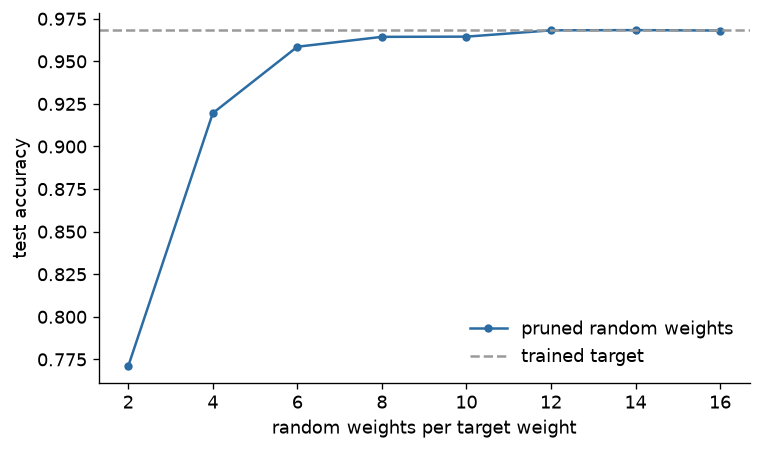

In [11]:
rows = []
for pool_size in (2, 4, 6, 8, 10, 12, 14, 16):
    tickets, accuracy = [], []
    for model, (_, X_test, _, y_test) in zip(models, splits):
        for seed in range(3):
            ticket = TicketLinear(model.coef_, model.intercept_, pool_size, seed=seed)
            tickets.append(ticket)
            accuracy.append((ticket.predict(X_test) == y_test).mean())
    rows.append(
        {
            "pool_size": pool_size,
            "accuracy": np.mean(accuracy),
            "worst": np.min(accuracy),
            "sparsity": np.mean([t.sparsity for t in tickets]),
            "max_error": np.mean([t.max_error for t in tickets]),
        }
    )
print("pool  accuracy  worst ticket  sparsity  max error")
for r in rows:
    print(f"{r['pool_size']:4d}  {r['accuracy']:8.4f}  {r['worst']:12.4f}  {r['sparsity']:8.2f}  {r['max_error']:9.4f}")
plots.plot_ticket(rows, target_accuracy)